Heart Attack Risk Prediction Using Machine Learning

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
heart = pd.read_csv('/content/drive/My Drive/framingham.csv')
heart.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


https://www.kaggle.com/datasets/christofel04/cardiovascular-study-dataset-predict-heart-disea

In [8]:
heart.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4240 entries, 0 to 4239
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4240 non-null   int64  
 1   age              4240 non-null   int64  
 2   education        4135 non-null   float64
 3   currentSmoker    4240 non-null   int64  
 4   cigsPerDay       4211 non-null   float64
 5   BPMeds           4187 non-null   float64
 6   prevalentStroke  4240 non-null   int64  
 7   prevalentHyp     4240 non-null   int64  
 8   diabetes         4240 non-null   int64  
 9   totChol          4190 non-null   float64
 10  sysBP            4240 non-null   float64
 11  diaBP            4240 non-null   float64
 12  BMI              4221 non-null   float64
 13  heartRate        4239 non-null   float64
 14  glucose          3852 non-null   float64
 15  TenYearCHD       4240 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 530.1 KB


In [9]:
heart.shape

(4240, 16)

In [10]:
heart.describe()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
count,4240.000000,4240.000000,4135.000000,4240.000000,4211.000000,4187.000000,4240.000000,4240.000000,4240.000000,4190.000000,4240.000000,4240.000000,4221.000000,4239.000000,3852.000000,4240.000000
mean,0.429245,49.580189,1.979444,0.494104,9.005937,0.029615,0.005896,0.310613,0.025708,236.699523,132.354599,82.897759,25.800801,75.878981,81.963655,0.151887
std,0.495027,8.572942,1.019791,0.500024,11.922462,0.169544,0.076569,0.462799,0.158280,44.591284,22.033300,11.910394,4.079840,12.025348,23.954335,0.358953
min,0.000000,32.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,107.000000,83.500000,48.000000,15.540000,44.000000,40.000000,0.000000
25%,0.000000,42.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,206.000000,117.000000,75.000000,23.070000,68.000000,71.000000,0.000000
50%,0.000000,49.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,128.000000,82.000000,25.400000,75.000000,78.000000,0.000000
75%,1.000000,56.000000,3.000000,1.000000,20.000000,0.000000,0.000000,1.000000,0.000000,263.000000,144.000000,90.000000,28.040000,83.000000,87.000000,0.000000
max,1.000000,70.000000,4.000000,1.000000,70.000000,1.000000,1.000000,1.000000,1.000000,696.000000,295.000000,142.500000,56.800000,143.000000,394.000000,1.000000


In [11]:
heart.isnull().sum()

,0
male,0
age,0
education,105
currentSmoker,0
cigsPerDay,29
BPMeds,53
prevalentStroke,0
prevalentHyp,0
diabetes,0
totChol,50


In [12]:
heart_fill = heart


In [13]:
heart_fill["cigsPerDay"].fillna(heart_fill.groupby("currentSmoker")["cigsPerDay"].transform("mean"), inplace=True)


/tmp/ipykernel_3549/349804703.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  heart_fill["cigsPerDay"].fillna(heart_fill.groupby("currentSmoker")["cigsPerDay"].transform("mean"), inplace=True)


In [14]:
heart_fill["BPMeds"].fillna(heart_fill.groupby("prevalentHyp")["BPMeds"].transform('median'), inplace=True)

/tmp/ipykernel_3549/758795261.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  heart_fill["BPMeds"].fillna(heart_fill.groupby("prevalentHyp")["BPMeds"].transform('median'), inplace=True)


In [15]:
heart_fill["totChol"].fillna(heart_fill.groupby("prevalentStroke")["totChol"].transform("mean"), inplace=True)

/tmp/ipykernel_3549/3851056283.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  heart_fill["totChol"].fillna(heart_fill.groupby("prevalentStroke")["totChol"].transform("mean"), inplace=True)


In [16]:
heart_fill["BMI"].fillna(heart_fill.groupby("age")["BMI"].transform("mean"), inplace=True)

/tmp/ipykernel_3549/2436366688.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  heart_fill["BMI"].fillna(heart_fill.groupby("age")["BMI"].transform("mean"), inplace=True)


In [17]:
heart_fill["heartRate"].fillna(heart_fill.groupby("sysBP")["heartRate"].transform("mean"), inplace=True)

/tmp/ipykernel_3549/342602063.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  heart_fill["heartRate"].fillna(heart_fill.groupby("sysBP")["heartRate"].transform("mean"), inplace=True)


In [18]:
heart_fill["glucose"].fillna(heart_fill.groupby("diabetes")["glucose"].transform("mean"), inplace=True)

/tmp/ipykernel_3549/819939993.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  heart_fill["glucose"].fillna(heart_fill.groupby("diabetes")["glucose"].transform("mean"), inplace=True)


In [19]:
heart_fill["education"].fillna(heart_fill.groupby("age")["education"].transform("mean"), inplace=True)

/tmp/ipykernel_3549/1894902592.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  heart_fill["education"].fillna(heart_fill.groupby("age")["education"].transform("mean"), inplace=True)


In [20]:
heart_fill.isnull().sum()

,0
male,0
age,0
education,0
currentSmoker,0
cigsPerDay,0
BPMeds,0
prevalentStroke,0
prevalentHyp,0
diabetes,0
totChol,0


In [21]:
heart_fill.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


Check For Correlation between attributes

<Axes: >

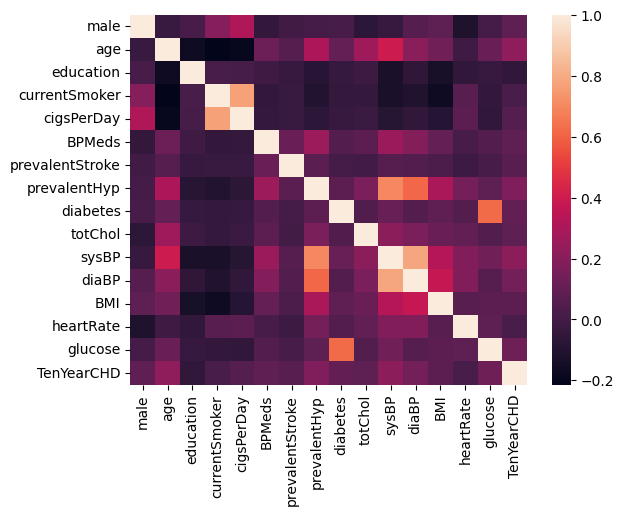

In [22]:
sns.heatmap(heart_fill.corr())

In [23]:
heart_fill.corr()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
male,1.000000,-0.029014,0.017432,0.197026,0.315941,-0.051544,-0.004550,0.005853,0.015693,-0.070064,-0.035879,0.058199,0.081560,-0.116842,0.006970,0.088374
age,-0.029014,1.000000,-0.168494,-0.213662,-0.192278,0.121011,0.057679,0.306799,0.101314,0.260691,0.394053,0.205586,0.137230,-0.012736,0.115184,0.225408
education,0.017432,-0.168494,1.000000,0.019835,0.009623,-0.010829,-0.035082,-0.081434,-0.039100,-0.023533,-0.129299,-0.061248,-0.136975,-0.052901,-0.033630,-0.053987
currentSmoker,0.197026,-0.213662,0.019835,1.000000,0.770882,-0.048348,-0.032980,-0.103710,-0.044285,-0.046211,-0.130281,-0.107933,-0.167691,0.062740,-0.052425,0.019448
cigsPerDay,0.315941,-0.192278,0.009623,0.770882,1.000000,-0.046521,-0.033056,-0.067109,-0.037881,-0.025251,-0.088293,-0.055936,-0.092859,0.076015,-0.053632,0.056284
BPMeds,-0.051544,0.121011,-0.010829,-0.048348,-0.046521,1.000000,0.114614,0.258580,0.051407,0.078775,0.251479,0.192254,0.099960,0.015126,0.048066,0.086448
prevalentStroke,-0.004550,0.057679,-0.035082,-0.032980,-0.033056,0.114614,1.000000,0.074791,0.006955,0.000105,0.057000,0.045153,0.029945,-0.017678,0.018070,0.061823
prevalentHyp,0.005853,0.306799,-0.081434,-0.103710,-0.067109,0.258580,0.074791,1.000000,0.077752,0.162683,0.696656,0.615840,0.301548,0.146867,0.082116,0.177458
diabetes,0.015693,0.101314,-0.039100,-0.044285,-0.037881,0.051407,0.006955,0.077752,1.000000,0.040161,0.111265,0.050260,0.086379,0.048976,0.625065,0.097344
totChol,-0.070064,0.260691,-0.023533,-0.046211,-0.025251,0.078775,0.000105,0.162683,0.040161,1.000000,0.207436,0.163423,0.114018,0.090653,0.044080,0.081807


array([[<Axes: title={'center': 'male'}>,
        <Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'education'}>,
        <Axes: title={'center': 'currentSmoker'}>],
       [<Axes: title={'center': 'cigsPerDay'}>,
        <Axes: title={'center': 'BPMeds'}>,
        <Axes: title={'center': 'prevalentStroke'}>,
        <Axes: title={'center': 'prevalentHyp'}>],
       [<Axes: title={'center': 'diabetes'}>,
        <Axes: title={'center': 'totChol'}>,
        <Axes: title={'center': 'sysBP'}>,
        <Axes: title={'center': 'diaBP'}>],
       [<Axes: title={'center': 'BMI'}>,
        <Axes: title={'center': 'heartRate'}>,
        <Axes: title={'center': 'glucose'}>,
        <Axes: title={'center': 'TenYearCHD'}>]], dtype=object)

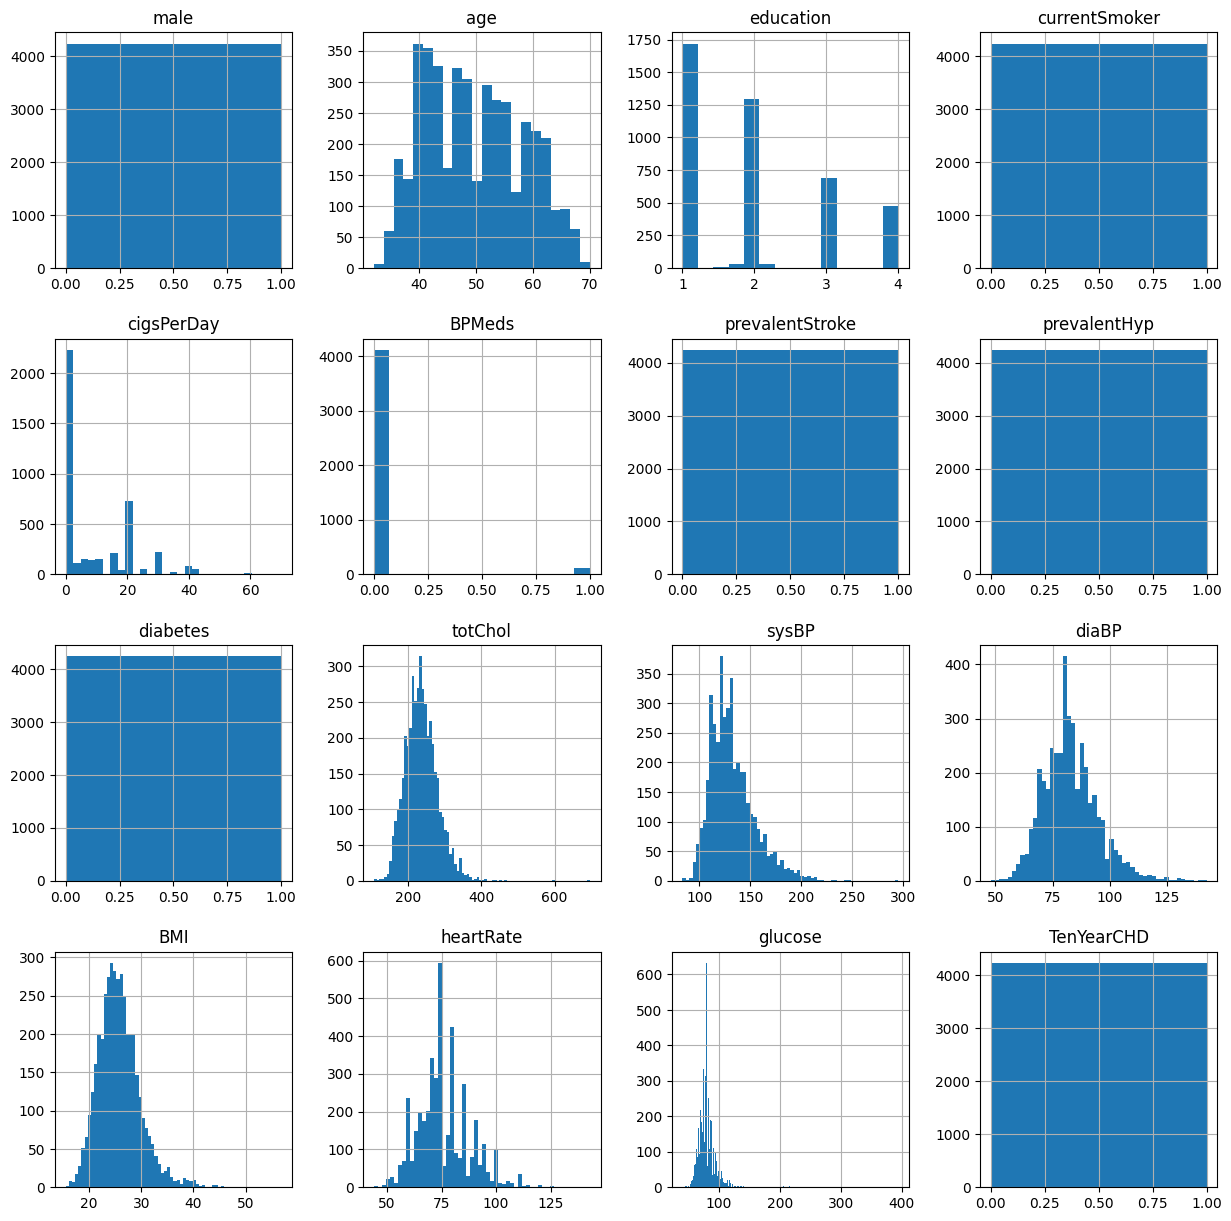

In [24]:
#To see the distribution and also see relationships between features
heart_fill.hist(bins='auto', figsize=(15,15))

<Axes: xlabel='TenYearCHD'>

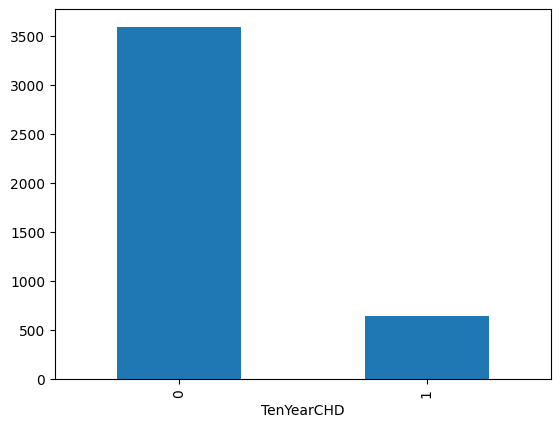

In [25]:
heart_fill['TenYearCHD'].value_counts().plot(x =heart_fill['TenYearCHD'], kind='bar')

In [26]:
heart_fill['TenYearCHD'].value_counts(normalize=True) * 100

,proportion
TenYearCHD,
0,84.811321
1,15.188679


<Axes: xlabel='gender', ylabel='count'>

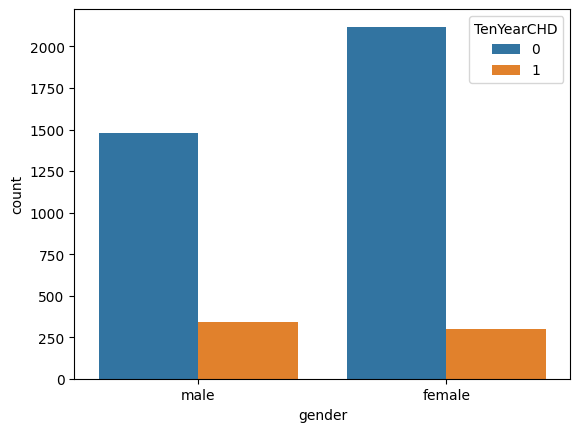

In [27]:
heart_fill_plot = heart_fill.copy()
heart_fill_plot['male']  = heart_fill_plot['male'].replace({0: 'female', 1:'male'})
heart_fill_plot = heart_fill_plot.rename(columns={'male':'gender'})
sns.countplot(data=heart_fill_plot, x='gender', hue='TenYearCHD')

In [28]:
#people who would not have a heart disease in 10 years
heart_fill[heart_fill['TenYearCHD']==0]['male'].value_counts(normalize = True) * 100

,proportion
male,
0,58.926585
1,41.073415


In [29]:
#people with diabetes who have the chance of having a heart disease in 10 years
heart_fill[heart_fill['diabetes']==1]['TenYearCHD'].value_counts(normalize = True) * 100

,proportion
TenYearCHD,
0,63.302752
1,36.697248


In [30]:
#people without diabetes who have the chance of having a heart disease in 10 years
heart_fill[heart_fill['diabetes']==0]['TenYearCHD'].value_counts(normalize = True) * 100

,proportion
TenYearCHD,
0,85.378843
1,14.621157


<Axes: xlabel='currentSmoker', ylabel='count'>

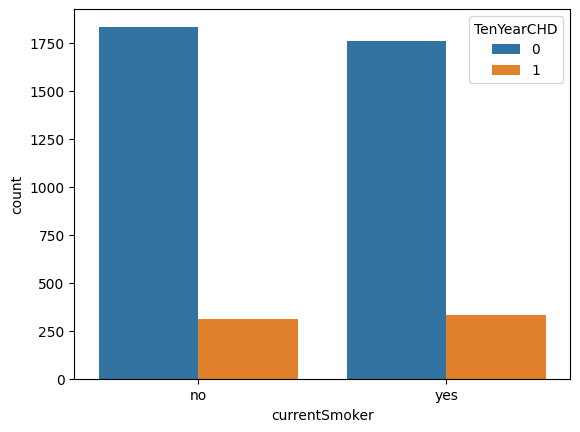

In [31]:
heart_fill_plot['currentSmoker']  = heart_fill_plot['currentSmoker'].replace({0: 'no', 1:'yes'})
sns.countplot(data=heart_fill_plot, x='currentSmoker', hue='TenYearCHD')

In [32]:
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import confusion_matrix, accuracy_score

In [33]:
#intialize model
lr = LogisticRegression()

In [34]:
def predict_70_30(df, target):
    split = StratifiedShuffleSplit(n_splits = 1, test_size=0.3, random_state=42)
    for train_index, test_index in split.split(df, df[target]):
        train = df.loc[train_index]
        test = df.loc[test_index]

        x = train.drop([target], axis=1)
        y = train[target]

        a = test.drop([target], axis=1)
        b = test[target]

        lr.fit(x,y)

        predicted = lr.predict(a)
        accuracy = accuracy_score(b, predicted)
        c_m = confusion_matrix(b, predicted)

        return print('Accuracy score: ', accuracy, '\n', 'Confusion matrix: ', c_m)

In [35]:
predict_70_30(heart_fill, 'TenYearCHD')

Accuracy score:  0.8498427672955975 
 Confusion matrix:  [[1073    6]
 [ 185    8]]


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
